二维稳态热传导方程求解(Jacobi迭代法)

一、问题背景

考虑一块正方形的金属钢板(1×1),边界温度固定：

左边界：100℃

上、下、右边界：0℃

求解钢板内部各点的稳定温度分布。

这是一个典型的稳态(无时间项)热传导问题。

二、数学模型（偏微分方程）

根据能量守恒，稳态下温度不随时间变化，得到二维泊松方程（拉普拉斯方程特例）：

$$ \frac{\partial^2 T}{\partial x^2} + \frac{\partial^2 T}{\partial y^2} = 0 $$

三、离散化（五点差分格式）（把连续方程变成算术题）

用泰勒展开对二阶导数进行近似，将钢板切成 N x N 的网格。

对于网格内部任意点 (i, j)，离散化后得到**五点差分格式**：
$$ T_{i,j} = \frac{1}{4} (T_{i+1,j} + T_{i-1,j} + T_{i,j+1} + T_{i,j-1}) $$
物理含义：每个内部点的温度，等于上下左右四个邻居点温度的平均值。

四、伪代码

输入：网格尺寸N，容差tol，最大迭代max_iter

初始化:创建一个N×N的温度矩阵T，全部设为0

设置边界条件：

    T[0,:]=0 // 上边界0度
    T[N-1,:]=0  // 下边界0度
    T[:,0]=100  // 左边界100度
    T[:,N-1]=0  //  右边界0度

迭代过程：

    对于k=1到N-1:
    
        创建一个T_new,全设为0

        error=0

        遍历内部所有点（i=1到N-2,j=1到N-2）：

            T_new[i,j]=(T[i-1,j]+T[i+1,j]+T[i,j-1]+T[i,j+1])/4

            error=max(error,abs(T_new[i,j]-T[i,j]))

        把边界条件赋给T_new

        如果error<tol:跳出循环

        更新旧值：T=T_new

输出：温度矩阵T
        

五、代码

In [3]:

import numpy as np
import matplotlib.pyplot as plt

def jacobi_heat_2d(N, tol=1e-4, max_iter=2000):
    # 1. 初始化
    T = np.zeros((N, N))
    
    # 2. 设置边界条件
    T[0, :] = 0      # 上边界
    T[N-1, :] = 0    # 下边界
    T[:, 0] = 100    # 左边界
    T[:, N-1] = 0    # 右边界
    
    error_history = []
    
    # 3. 迭代过程
    for k in range(max_iter):
        T_new = np.zeros((N, N))
        error = 0.0
        
        # 遍历内部点
        for i in range(1, N-1):
            for j in range(1, N-1):
                T_new[i, j] = (T[i-1, j] + T[i+1, j] + T[i, j-1] + T[i, j+1]) / 4.0
                error = max(error, abs(T_new[i, j] - T[i, j]))
        
        # 边界条件重新赋值
        T_new[0, :] = 0
        T_new[N-1, :] = 0
        T_new[:, 0] = 100
        T_new[:, N-1] = 0
        
        error_history.append(error)
        
        # 判断收敛
        if error < tol:
            print(f"在第 {k+1} 次迭代时收敛，误差 = {error:.6e}")
            break
            
        T = T_new.copy()
        
    return T, error_history

六、结果验证与可视化

C:\Users\86159\AppData\Local\Temp\ipykernel_24140\3666658531.py:23: UserWarning: Glyph 28201 (\N{CJK UNIFIED IDEOGRAPH-6E29}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\86159\AppData\Local\Temp\ipykernel_24140\3666658531.py:23: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
D:\miniconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 28201 (\N{CJK UNIFIED IDEOGRAPH-6E29}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\miniconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


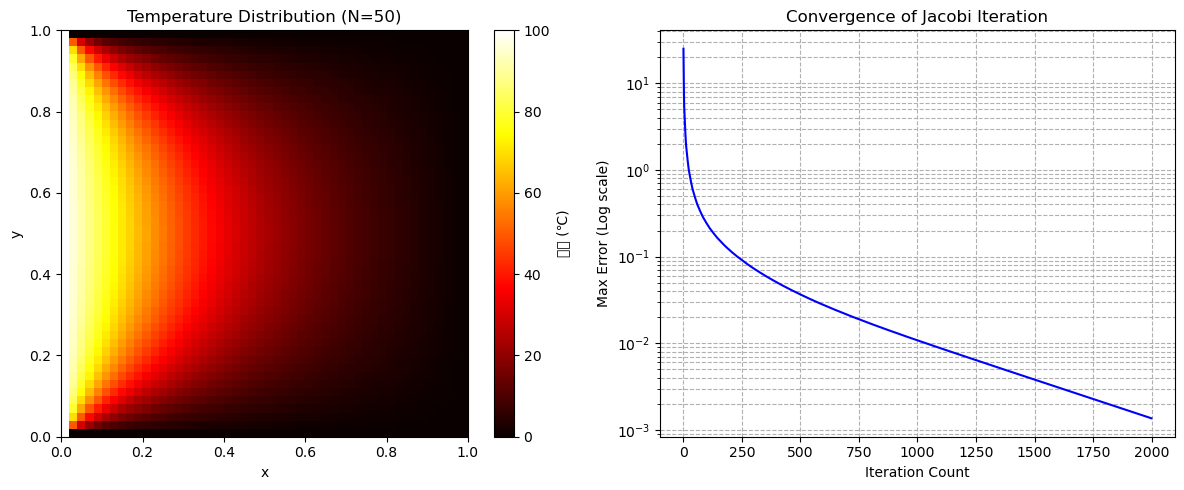

In [4]:
# 运行求解
N = 50
T, errors = jacobi_heat_2d(N, tol=1e-4, max_iter=2000)

# 画热力图
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(T, cmap='hot', origin='lower', extent=[0, 1, 0, 1])
plt.colorbar(label='温度 (℃)')
plt.title(f'Temperature Distribution (N={N})') # 为避免中文乱码，这里用英文
plt.xlabel('x')
plt.ylabel('y')

# 画误差收敛曲线
plt.subplot(1, 2, 2)
plt.semilogy(errors, 'b-')
plt.xlabel('Iteration Count')
plt.ylabel('Max Error (Log scale)')
plt.title('Convergence of Jacobi Iteration')
plt.grid(True, which="both", ls="--")

plt.tight_layout()
plt.show()

七、性能测试

In [5]:
import time

# 测试不同网格尺寸的耗时和迭代次数
for n in [20, 50, 100]:
    start_time = time.time()
    _, errs = jacobi_heat_2d(n, tol=1e-4, max_iter=5000)
    end_time = time.time()
    print(f"网格尺寸 N={n:3d} | 耗时={end_time - start_time:.4f}秒 | 迭代次数={len(errs)}")

在第 628 次迭代时收敛，误差 = 9.957901e-05
网格尺寸 N= 20 | 耗时=0.3106秒 | 迭代次数=628
在第 3270 次迭代时收敛，误差 = 9.995464e-05
网格尺寸 N= 50 | 耗时=11.4080秒 | 迭代次数=3270
网格尺寸 N=100 | 耗时=73.2644秒 | 迭代次数=5000


八、记录与反思

-收敛性：Jacobi迭代对严格对角占优矩阵收敛。本次钢板温度矩阵是对角占优的，迭代正常收敛。

- **性能规律**：网格越大（N越大），迭代次数越多，单次迭代耗时也越长。

- **AI 代码问题记录**：AI生成的代码最初没有正确处理边界条件的重新赋值，导致边界温度在迭代中被侵蚀。
我手动加入了边界重设，并使用了 `T = T_new.copy()` 避免了变量引用混乱。


- **英语问题**：画图标签一律用英文，避免 Matplotlib 中文字体乱码。